# E-bike pack real-road logs with a faulty parallel group

This notebook lists the one e-bike pack and its six recordings in the Zenodo release, loads the raw ride logged before a faulty parallel group was replaced, and plots the 13 parallel-group voltages. It makes no diagnosis.

## 1. Released units

This step lists what `systems('giu_ebike')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('giu_ebike')
display(released)

,unit,topology,cells,cell_model,bms,nominal_v,recordings
0,pack,13S4P,52,Samsung INR18650-30Q,JK-BMS JK_BD6A20S6P,48.0,6


The release is one 48 V e-bike pack of 52 Samsung INR18650-30Q cells in 13 parallel groups of four (13S4P), read by a JK-BMS, as its README states. Its six recordings are all of this pack, five cleaned files after the repair and one raw log before it. The per-recording profile behind the claims in this notebook is saved in `reports/candidates/giu_ebike/giu_ebike_profile.csv`, made by `scripts/facts/giu_ebike.py`.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
from fielddata.loaders import giu_ebike
display(giu_ebike.recordings())
frame = load('giu_ebike', recording='raw/jk_001_before_repair')
print(frame.shape)
display(frame.head())

,recording,rows,first,last,time_basis,phases
0,1_capacity_test,31757,2026-11-06 21:20:05,2026-11-07 06:15:18,"local, UTC+2",rest;charge;ride1;ride2;ride3;ride4;ride5;moto...
1,2_charge_and_ride_A,30853,2026-11-07 11:35:48,2026-11-07 20:10:00,"local, UTC+2",rest;charge;ride_A
2,3_ride_B,8983,2026-11-08 12:00:18,2026-11-08 14:30:00,"local, UTC+2",rest;ride_B
3,4_ride_C,5202,2026-11-08 18:25:39,2026-11-08 19:52:20,"local, UTC+2",rest;ride_C
4,5_charge_after_rides,23873,2026-11-08 23:19:08,2026-11-09 05:57:00,"local, UTC+2",rest;charge
5,raw/jk_001_before_repair,1305,2026-10-29 23:15:08+00:00,2026-10-29 23:36:52+00:00,UTC,


(1305, 28)


,recording,utc_time,time_source,uptime_ms,jk_age_ms,pack_V,current_A,charge_Ah,t_pack_C,t_amb_C,...,cell04,cell05,cell06,cell07,cell08,cell09,cell10,cell11,cell12,cell13
0,raw/jk_001_before_repair,2026-10-29 23:15:08+00:00,ntp,8904,133,52.788,-0.0,0.0,21.44,19.62,...,4.055,4.059,4.059,4.057,4.080,4.06,4.061,4.06,4.057,4.060
1,raw/jk_001_before_repair,2026-10-29 23:15:09+00:00,ntp,9904,33,52.787,-0.0,0.0,21.44,19.62,...,4.055,4.059,4.059,4.056,4.078,4.06,4.061,4.06,4.059,4.059
2,raw/jk_001_before_repair,2026-10-29 23:15:10+00:00,ntp,10904,493,52.787,-0.0,0.0,21.44,19.62,...,4.055,4.059,4.059,4.057,4.080,4.06,4.061,4.06,4.059,4.060
3,raw/jk_001_before_repair,2026-10-29 23:15:11+00:00,ntp,11904,413,52.787,-0.0,0.0,21.44,19.56,...,4.055,4.059,4.059,4.056,4.078,4.06,4.061,4.06,4.059,4.060
4,raw/jk_001_before_repair,2026-10-29 23:15:12+00:00,ntp,12904,313,52.788,-0.0,0.0,21.44,19.62,...,4.055,4.059,4.059,4.057,4.078,4.06,4.061,4.06,4.059,4.060


The table lists the six recordings with their rows, first and last time and phases. The cleaned files keep local time (UTC+2) and the raw file keeps UTC, as released. The raw pre-repair log has 1,305 one-second lines and 28 columns, as released, with the loader's `recording` column added. Its columns differ from the cleaned files and are described in the schema note.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['pack_V', 'current_A', 'cell01', 'cell08', 't_pack_C']].describe().T)

,count,mean,std,min,25%,50%,75%,max
pack_V,1305.0,51.016799,1.243638,45.545,50.920,51.492,51.632,52.789
current_A,1305.0,2.841211,5.808318,-0.223,0.000,0.000,0.000,16.182
cell01,1305.0,3.950130,0.058765,3.796,3.944,3.970,3.975,4.059
cell08,1305.0,3.629921,0.553432,0.000,3.588,3.843,3.921,4.080
t_pack_C,1273.0,23.257031,1.209970,21.440,22.000,23.380,24.500,24.880


These ranges are raw values of the pre-repair log, as released, before any cleaning. Current runs from -0.223 to 16.182 A and is positive in discharge. Group 1 stays between 3.796 and 4.059 V. Group 8 ranges from 0.000 to 4.080 V. The 0 V readings are kept because low cell voltage can be real fault data. `t_pack_C` has 1,273 of 1,305 values, the rest missing as released.

## 4. A first look

This step plots one signal to show the shape of the data.

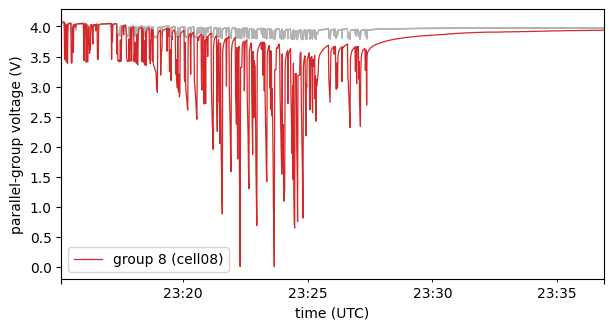

In [4]:
cells = [f'cell{i:02d}' for i in range(1, 14)]
ax = frame.plot(x='utc_time', y=[c for c in cells if c != 'cell08'], color='0.7', lw=0.6, legend=False, figsize=(7, 3.5))
frame.plot(x='utc_time', y='cell08', color='C3', lw=0.9, ax=ax, label='group 8')
ax.set_xlabel('time (UTC)')
ax.set_ylabel('parallel-group voltage (V)')
ax.legend([ax.lines[-1]], ['group 8 (cell08)'])
plt.show()

During the ride, group 8 (red) drops far below the other twelve groups (grey) whenever current flows, while the others stay near 3.8 to 4.0 V, raw. It falls below 2.5 V on 64 of the one-second lines and reads 0 V twice, as `group8.txt` records. After the ride it recovers slowly toward the others. The README says the four cells of this group were replaced on 6 November 2026, before the five cleaned recordings.